# CSC 4110 Machine Learning: task notebook


| Field | Fill in |
|---|---|
| Task | 3.2 Polynomial and regularised regression |
| Owner (name) | Peter Mbugua |
| Registration number | COM/0039/23 |
| Group | G04 |
| Dataset | Credit Risk Dataset |
| Date started | 26 November 2026 |


**Rules**
- Save this file in your group folder as `G<No>_U<task>_<short name>.ipynb`, exactly as shown under **Save as** in your group's paper, e.g. `G01_U2.1_cleaning.ipynb`.
- One Markdown heading per part, then its code cells. Comment every code cell.
- Use the exact variable and file names in **Graded evidence** of your task, and `random_state=42` everywhere.
- Reviewers add a cell headed **Review by <Name>** in the Reviews section. They never edit the owner's cells.

In [1]:
# Setup: set your group and task, connect Google Drive, and work inside the group folder
GROUP = "G04"        # your group, two digits
UNIT = "3.2"         # your task number: 2.1, 2.2, 3.1, 3.2, 4, 5, 6, 7, 8, 9.1, 9.2 or 9.3
RANDOM_STATE = 42    # use this everywhere so the grader gets the same numbers

import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive not mounted here:", e)   # normal when the grader runs this notebook

BASE = f"/content/drive/MyDrive/CSC4110_{GROUP}"
for sub in ["data", "notebooks", "models", "outputs", "app", "report", "tests"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
os.chdir(BASE)   # every path below is relative to the group folder
print("Working in", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in /content/drive/.shortcut-targets-by-id/1Hfur0Lf8z0gktOkV4oQdkhdGubaALOUm/CSC4110_G04


In [2]:
# Libraries used in most tasks, and a helper that saves every chart to outputs/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def save_fig(name):
    """Save the current chart as outputs/<name>.png, then show it."""
    path = f"outputs/{name}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    print("Saved", path)
    plt.show()

## Load the data

- Task 2.1 loads the original Kaggle file.
- Task 2.2 loads `data/stage1_<dataset>.csv`.
- Every other task loads `data/clean_<dataset>.csv`.

In [3]:

# Task 3.2: Load the prepared Credit Risk Dataset

# Use the dataset prepared by Collins Kipkorir
DATA_FILE = "data/clean_credit.csv"

# Load the dataset
df = pd.read_csv(DATA_FILE)

# Display its dimensions
print("Dataset shape:", df.shape)

# Display the first five records
display(df.head())

# Count records with originally observed interest rates
observed_rates = (df["rate_imputed"] == 0).sum()

print("Observed interest rates:", observed_rates)


Dataset shape: (32409, 25)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,...,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,age_band,log_income
0,21,9600,OWN,5.0,EDUCATION,1,1000,11.14,0,0.10,...,1,0,0,1,0,0,0,0,under 25,9.169518
1,25,9600,MORTGAGE,1.0,MEDICAL,2,5500,12.87,1,0.57,...,0,0,0,0,0,1,0,0,25-34,9.169518
2,23,65500,RENT,4.0,MEDICAL,2,35000,15.23,1,0.53,...,0,1,0,0,0,1,0,0,under 25,11.089805
3,24,54400,RENT,8.0,MEDICAL,2,35000,14.27,1,0.55,...,0,1,0,0,0,1,0,0,under 25,10.904119
4,21,9900,OWN,2.0,VENTURE,0,2500,7.14,1,0.25,...,1,0,0,0,0,0,0,1,under 25,9.200290


Observed interest rates: 29315



## Task 3.2(a): Polynomial Regression

This section prepares the regression dataset using the same training and testing split as Task 3.1. I will then compare polynomial regression models of degrees 1, 2 and 3.


In [4]:

# Task 3.2: Prepare regression data using the same split as Task 3.1

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Use only loans with originally observed interest rates
regression_data = df[df["rate_imputed"] == 0].copy()

# Select the interest rate as our target
y = regression_data["loan_int_rate"]

# Select numerical features and remove leakage columns
X = regression_data.select_dtypes(include="number").drop(
    columns=[
        "loan_int_rate",
        "loan_grade",
        "loan_status",
        "rate_imputed"
    ]
)

# Split into 80% training and 20% testing
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Fit the scaler using training data only
scaler = StandardScaler()

# Scale training data
X_train = pd.DataFrame(
    scaler.fit_transform(X_train_raw),
    columns=X.columns,
    index=X_train_raw.index
)

# Scale test data using the same scaler
X_test = pd.DataFrame(
    scaler.transform(X_test_raw),
    columns=X.columns,
    index=X_test_raw.index
)

# Display the results
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of features:", X_train.shape[1])

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

# Confirm log_income is available for polynomial regression
assert "log_income" in X_train.columns

print("\nData preparation completed successfully!")


Training records: 23452
Testing records: 5863
Number of features: 18

Training shape: (23452, 18)
Testing shape: (5863, 18)

Data preparation completed successfully!


In [5]:

# Task 3.2(a): Compare polynomial regression models

# Import the required machine learning tools
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Use only log_income for this polynomial experiment
X_poly_train = X_train[["log_income"]]
X_poly_test = X_test[["log_income"]]

# Store results and trained models
poly_results = {}
poly_models = {}

# Test polynomial degrees 1, 2 and 3
for degree in [1, 2, 3]:

    # Create a pipeline with polynomial features and regression
    model = Pipeline([
        ("poly", PolynomialFeatures(
            degree=degree,
            include_bias=False
        )),
        ("regression", LinearRegression())
    ])

    # Train the model on the training set
    model.fit(X_poly_train, y_train)

    # Predict on training and testing data
    train_pred = model.predict(X_poly_train)
    test_pred = model.predict(X_poly_test)

    # Calculate training and testing RMSE
    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_pred)
    )

    test_rmse = np.sqrt(
        mean_squared_error(y_test, test_pred)
    )

    # Save the required results
    poly_results[degree] = {
        "train_rmse": train_rmse,
        "test_rmse": test_rmse
    }

    # Save the model for later comparison
    poly_models[degree] = model

# Display the comparison table
poly_table = pd.DataFrame.from_dict(
    poly_results,
    orient="index"
)

poly_table.index.name = "Polynomial Degree"

print("POLYNOMIAL REGRESSION RESULTS")
display(poly_table.round(4))

# Identify the degree with the lowest test RMSE
best_degree = poly_table["test_rmse"].idxmin()

print("Lowest test RMSE degree:", best_degree)
print("Test RMSE:", round(
    poly_table.loc[best_degree, "test_rmse"], 4
))

print("\nPolynomial regression completed successfully!")


POLYNOMIAL REGRESSION RESULTS


,train_rmse,test_rmse
Polynomial Degree,,
1,3.2410,3.2380
2,3.2400,3.2385
3,3.2388,3.2374


Lowest test RMSE degree: 3
Test RMSE: 3.2374

Polynomial regression completed successfully!


UNDERFITTING / OVERFITTING COMPARISON


,train_rmse,test_rmse
1,3.2410,3.2380
3,3.2388,3.2374
10,3.2372,3.2378


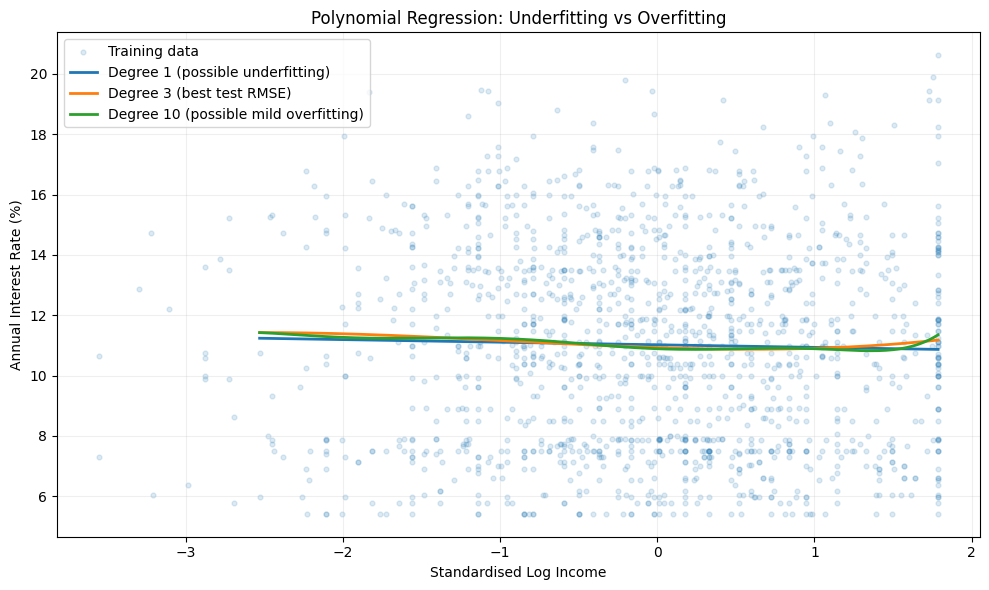

Saved: outputs/under_over_fit.png


In [6]:

# Task 3.2(a): Demonstrate underfitting and overfitting

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Store the three models and their evaluation results
curve_models = {}
curve_results = {}

# Train polynomial models of degrees 1, 3 and 10
for degree in [1, 3, 10]:

    model = Pipeline([
        ("polynomial", PolynomialFeatures(
            degree=degree,
            include_bias=False
        )),
        ("regression", LinearRegression())
    ])

    # Fit using the same scaled log_income training feature
    model.fit(X_poly_train, y_train)

    # Evaluate on training and testing data
    train_predictions_curve = model.predict(X_poly_train)
    test_predictions_curve = model.predict(X_poly_test)

    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_predictions_curve)
    )

    test_rmse = np.sqrt(
        mean_squared_error(y_test, test_predictions_curve)
    )

    curve_models[degree] = model
    curve_results[degree] = {
        "train_rmse": train_rmse,
        "test_rmse": test_rmse
    }

# Display RMSE comparison
print("UNDERFITTING / OVERFITTING COMPARISON")
display(pd.DataFrame.from_dict(
    curve_results, orient="index"
).round(4))

# Create a smooth range for drawing the fitted curves
x_min = X_poly_train["log_income"].quantile(0.01)
x_max = X_poly_train["log_income"].quantile(0.99)

x_line = pd.DataFrame({
    "log_income": np.linspace(x_min, x_max, 300)
})

# Create the graph
plt.figure(figsize=(10, 6))

# Display a sample of training points for readability
sample = X_poly_train.sample(
    n=min(1500, len(X_poly_train)),
    random_state=42
)

plt.scatter(
    sample["log_income"],
    y_train.loc[sample.index],
    alpha=0.15,
    s=12,
    label="Training data"
)

# Plot the three polynomial regression curves
for degree in [1, 3, 10]:
    y_line = curve_models[degree].predict(x_line)

    plt.plot(
        x_line["log_income"],
        y_line,
        linewidth=2,

label={
    1: "Degree 1 (possible underfitting)",
    3: "Degree 3 (best test RMSE)",
    10: "Degree 10 (possible mild overfitting)"
}[degree]

    )

# Add title and axis labels
plt.title("Polynomial Regression: Underfitting vs Overfitting")
plt.xlabel("Standardised Log Income")
plt.ylabel("Annual Interest Rate (%)")

plt.legend()
plt.grid(alpha=0.2)

# Save the required graph
plt.tight_layout()
plt.savefig("outputs/under_over_fit.png", dpi=150)

# Display the graph
plt.show()

print("Saved: outputs/under_over_fit.png")



### Exam Skill: Underfitting and Overfitting

I compared polynomial regression models of degrees 1, 3 and 10 using log_income.

Degree 1 is the simplest model and may underfit because it can only represent a straight-line relationship.

Degree 3 achieved the lowest test RMSE of 3.2374, making it the best model among the three.

Degree 10 achieved a slightly lower training RMSE of 3.2372 but a higher testing RMSE of 3.2378 compared with Degree 3. This suggests mild overfitting, although the difference is very small.

Overall, increasing model complexity did not produce a substantial improvement in interest-rate prediction.



## Task 3.2(b): Ridge and Lasso Regression

In this section, I compare Ridge and Lasso regression models using alpha values of 0.01, 0.1, 1 and 10. I calculate the test RMSE for each model and count the coefficients that Lasso reduces to exactly zero.


In [7]:

# Task 3.2(b): Ridge and Lasso regression

from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error

# The four alpha values required by the lecturer
alphas = [0.01, 0.1, 1, 10]

# Store results and trained models
ridge_results = {}
lasso_results = {}
lasso_zero_counts = {}

ridge_models = {}
lasso_models = {}

# Test both models using every alpha value
for alpha in alphas:

    # RIDGE REGRESSION
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train, y_train)

    ridge_pred = ridge.predict(X_test)

    ridge_rmse = np.sqrt(
        mean_squared_error(y_test, ridge_pred)
    )

    ridge_results[alpha] = ridge_rmse
    ridge_models[alpha] = ridge

    # LASSO REGRESSION
    lasso = Lasso(
        alpha=alpha,
        max_iter=20000,
        random_state=42
    )

    lasso.fit(X_train, y_train)

    lasso_pred = lasso.predict(X_test)

    lasso_rmse = np.sqrt(
        mean_squared_error(y_test, lasso_pred)
    )

    lasso_results[alpha] = lasso_rmse
    lasso_models[alpha] = lasso

    # Count coefficients that are exactly zero
    lasso_zero_counts[alpha] = int(
        np.sum(lasso.coef_ == 0)
    )

# Display the comparison table
regularisation_table = pd.DataFrame({
    "Ridge Test RMSE": ridge_results,
    "Lasso Test RMSE": lasso_results,
    "Lasso Zero Coefficients": lasso_zero_counts
})

regularisation_table.index.name = "Alpha"

print("RIDGE AND LASSO REGRESSION RESULTS")
display(regularisation_table.round(4))

# Identify the lowest test RMSE for each method
best_ridge_alpha = min(ridge_results, key=ridge_results.get)
best_lasso_alpha = min(lasso_results, key=lasso_results.get)

print("\nBest Ridge alpha:", best_ridge_alpha)
print("Best Ridge RMSE:", round(
    ridge_results[best_ridge_alpha], 4
))

print("\nBest Lasso alpha:", best_lasso_alpha)
print("Best Lasso RMSE:", round(
    lasso_results[best_lasso_alpha], 4
))

print("\nRidge and Lasso comparison completed!")


RIDGE AND LASSO REGRESSION RESULTS


,Ridge Test RMSE,Lasso Test RMSE,Lasso Zero Coefficients
Alpha,,,
0.01,2.7171,2.7183,6
0.10,2.7171,2.7380,14
1.00,2.7171,2.9731,17
10.00,2.7171,3.2399,18



Best Ridge alpha: 0.01
Best Ridge RMSE: 2.7171

Best Lasso alpha: 0.01
Best Lasso RMSE: 2.7183

Ridge and Lasso comparison completed!



## Task 3.2(c): Comparison of Regression Models

This section compares multiple linear regression, polynomial regression, Ridge regression and Lasso regression using MAE, RMSE and R² on the same test records.


REGRESSION MODEL COMPARISON


,MAE,RMSE,R2
Multiple Linear,2.1889,2.7171,0.2966
Polynomial Degree 3,2.6909,3.2374,0.0015
Ridge,2.1889,2.7171,0.2966
Lasso,2.1897,2.7183,0.2960



Lowest test RMSE: Multiple Linear
RMSE: 2.7171


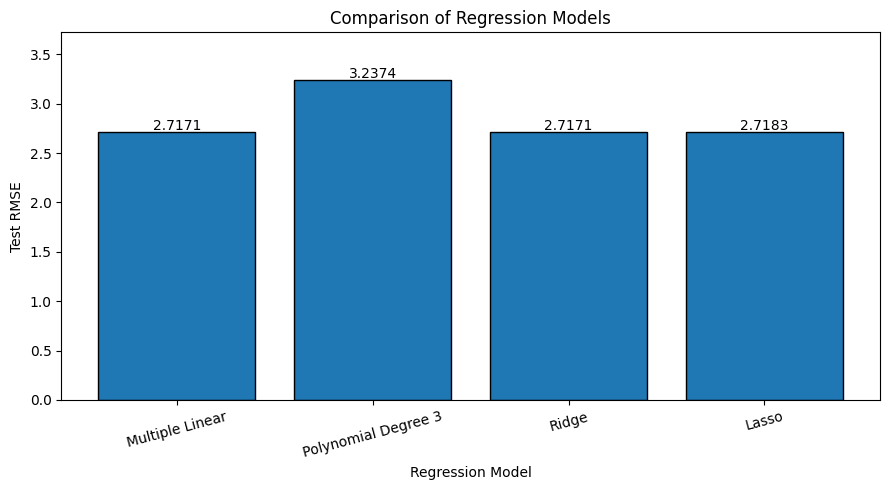


Saved: outputs/regression_comparison.png


In [8]:

# Task 3.2(c): Compare all regression models

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Refit multiple linear regression on the same split
lr_multi = LinearRegression()
lr_multi.fit(X_train, y_train)

# Collect the four models and their test inputs
models_to_compare = {
    "Multiple Linear": (lr_multi, X_test),
    f"Polynomial Degree {best_degree}": (
        poly_models[best_degree], X_poly_test
    ),
    "Ridge": (
        ridge_models[best_ridge_alpha], X_test
    ),
    "Lasso": (
        lasso_models[best_lasso_alpha], X_test
    )
}

# Evaluate each model on the test set
comparison = {}

for model_name, (model, test_features) in models_to_compare.items():

    # Predict the interest rates
    predictions = model.predict(test_features)

    # Calculate prediction errors
    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    # Store the results
    comparison[model_name] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

# Create the required comparison DataFrame
results_reg = pd.DataFrame.from_dict(
    comparison, orient="index"
)

print("REGRESSION MODEL COMPARISON")
display(results_reg.round(4))

# Identify the model with the lowest test RMSE
best_model_name = results_reg["RMSE"].idxmin()

print("\nLowest test RMSE:", best_model_name)
print("RMSE:", round(
    results_reg.loc[best_model_name, "RMSE"], 4
))

# Create the required comparison bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    results_reg.index,
    results_reg["RMSE"],
    edgecolor="black"
)

# Display RMSE values above the bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.02,
        f"{height:.4f}",
        ha="center"
    )

plt.title("Comparison of Regression Models")
plt.xlabel("Regression Model")
plt.ylabel("Test RMSE")

plt.xticks(rotation=15)
plt.ylim(0, results_reg["RMSE"].max() * 1.15)

# Save and display the chart
plt.tight_layout()
plt.savefig(
    "outputs/regression_comparison.png",
    dpi=150
)

plt.show()

print("\nSaved: outputs/regression_comparison.png")


In [9]:

# Task 3.2(c): Demonstrate data leakage using loan_grade

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 1. Evaluate the correct model without loan_grade
baseline_predictions = lr_multi.predict(X_test)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

# 2. Add loan_grade to the same training and test records
X_train_with_grade = X_train.copy()
X_test_with_grade = X_test.copy()

X_train_with_grade["loan_grade"] = regression_data.loc[
    X_train.index, "loan_grade"
]

X_test_with_grade["loan_grade"] = regression_data.loc[
    X_test.index, "loan_grade"
]

# 3. Train a new model that includes the leaked feature
leak_model = LinearRegression()

leak_model.fit(
    X_train_with_grade,
    y_train
)

# 4. Evaluate the model containing loan_grade
leak_predictions = leak_model.predict(X_test_with_grade)

leak_r2 = r2_score(
    y_test,
    leak_predictions
)

# 5. Calculate the change in R-squared
r2_jump = leak_r2 - baseline_r2

# Display results
print("DATA LEAKAGE EXPERIMENT")

print("R2 without loan_grade:", round(baseline_r2, 4))
print("R2 with loan_grade:", round(leak_r2, 4))
print("R2 increase:", round(r2_jump, 4))

print("\nIncrease in R2 percentage points:",
      round(r2_jump * 100, 2))

print("\nWARNING: loan_grade is derived from interest rate.")
print("It must not be used in the final interest-rate model.")


DATA LEAKAGE EXPERIMENT
R2 without loan_grade: 0.2966
R2 with loan_grade: 0.8668
R2 increase: 0.5702

Increase in R2 percentage points: 57.02

It must not be used in the final interest-rate model.


In [10]:

# Task 3.2(c): Identify influential regression features

# Extract coefficients from multiple linear regression
coefficients = pd.Series(
    lr_multi.coef_,
    index=X_train.columns
)

# Arrange features by absolute coefficient size
important_features = coefficients.abs().sort_values(
    ascending=False
)

# Display the ten largest coefficients
print("TOP 10 FEATURES BY ABSOLUTE COEFFICIENT")

feature_table = pd.DataFrame({
    "Coefficient": coefficients,
    "Absolute Coefficient": coefficients.abs()
})

feature_table = feature_table.sort_values(
    "Absolute Coefficient",
    ascending=False
)

display(feature_table.head(10).round(4))

# Print the top five features
print("\nTOP FIVE FEATURES:")

for feature in important_features.head(5).index:
    print(feature)

print("\nFeature analysis completed!")


TOP 10 FEATURES BY ABSOLUTE COEFFICIENT


,Coefficient,Absolute Coefficient
cb_person_default_on_file,1.5616,1.5616
loan_amnt,0.8702,0.8702
log_income,-0.4612,0.4612
loan_percent_income,-0.3919,0.3919
person_home_ownership_RENT,0.1944,0.1944
person_home_ownership_MORTGAGE,-0.1920,0.1920
person_emp_length,-0.0652,0.0652
cb_person_cred_hist_length,0.0648,0.0648
person_home_ownership_OTHER,0.0486,0.0486
loan_intent_HOMEIMPROVEMENT,0.0478,0.0478



TOP FIVE FEATURES:
cb_person_default_on_file
loan_amnt
log_income
loan_percent_income
person_home_ownership_RENT

Feature analysis completed!


## Part a) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [11]:
# a1. <what this cell does>


## Part b) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [12]:
# b1. <what this cell does>


## Part c) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [13]:
# c1. <what this cell does>


## Written answer

## Task 3.2: Written Answer — Regression Model Comparison

I compared Multiple Linear Regression, Polynomial Regression, Ridge Regression and Lasso Regression using the same training and testing split.

Multiple Linear Regression and Ridge performed almost equally, with a test RMSE of approximately **2.7171** and R² of **0.2966**, making them the strongest models among those tested.

The degree 3 polynomial model achieved a test RMSE of **3.2374**, but performed worse than the multiple-feature models because it used only `log_income`.

The degree 10 polynomial model showed a slight indication of overfitting, with training RMSE of **3.2372** and testing RMSE of **3.2378**, although the difference was very small.

The largest absolute standardised coefficients belonged to `cb_person_default_on_file` (1.5616), `loan_amnt` (0.8702), `log_income` (0.4612), `loan_percent_income` (0.3919) and `person_home_ownership_RENT` (0.1944); these associations do not necessarily establish causation.

Adding `loan_grade` increased R² from **0.2966 to 0.8668**, an increase of **0.5702**, but this was data leakage because loan grade is derived from interest rate and must therefore be excluded from the final interest-rate model.

## Reviews

### Review by <Name>
A check, an improvement or a question.

## Evidence checklist (tick before you submit)

- [ ] Runtime → Restart session and run all: no errors
- [ ] The basic check below shows no missing names or files
- [ ] The written answer is complete and quotes my numbers
- [ ] The self-check cell from Moodle passes
- [ ] File → Save, and File → Save a copy in GitHub

In [14]:
# Basic check: are the required variables and files there? (names and files only;
# the self-check cell on Moodle also tests the values)
import glob
REQUIRED = {
    "2.1": (["df_raw", "df_stage1", "outlier_col", "lower", "upper"], ["data/stage1_*.csv"]),
    "2.2": (["df_clean", "X_train", "X_test", "y_train", "y_test", "scaler"],
            ["data/clean_*.csv", "outputs/hist_target.png", "outputs/box_feature.png",
             "outputs/bar_class.png", "outputs/scatter_best.png", "outputs/corr_heatmap.png"]),
    "3.1": (["lr_simple", "lr_multi", "metrics_multi", "b0_gd", "b1_gd", "cost_history"],
            ["outputs/simple_fit.png", "outputs/actual_vs_pred.png", "outputs/gd_cost.png"]),
    "3.2": (["poly_results", "ridge_results", "lasso_results", "results_reg"],
            ["outputs/under_over_fit.png", "outputs/regression_comparison.png"]),
    "4":   (["y_train", "y_test", "log_reg", "cm", "results_clf"], ["outputs/confusion_matrix.png"]),
    "5":   (["pipe", "cv_scores", "grid", "test_score", "threshold_results"],
            ["outputs/learning_curve.png", "outputs/validation_curve.png"]),
    "6":   (["tree3", "ig_root", "depth_results", "results_trees", "importances"],
            ["outputs/tree_depth3.png", "outputs/depth_curve.png", "outputs/feature_importance.png"]),
    "7":   (["inertias", "sil_scores", "best_k", "pca", "dbscan_labels", "Q", "success_rates"],
            ["outputs/elbow.png", "outputs/pca_clusters.png", "outputs/success_rate.png"]),
    "8":   (["w_and", "b_and", "mlp_results", "best_mlp", "activation_results", "mlp_reg_rmse"], ["outputs/loss_curve.png"]),
    "9.1": (["final_pipe"], ["models/*_model.joblib", "app/app.py", "app/requirements.txt",
                             "outputs/app_screenshot.png"]),
    "9.2": (["fairness_table", "flagged"], ["outputs/fairness.csv", "outputs/fairness.png",
                                            "report/model_card.md"]),
    "9.3": ([], ["tests/smoke_test.py", "README.md"]),
}
names, files = REQUIRED[UNIT]
missing_names = [n for n in names if n not in globals()]
missing_files = [f for f in files if not glob.glob(f)]
print(f"Task {UNIT}")
print("Missing variables:", missing_names or "none")
print("Missing files:", missing_files or "none")
print("PASS" if not (missing_names or missing_files) else "FIX the items above before you submit")

Task 3.2
Missing variables: none
Missing files: none
PASS


## Self-check

Paste the self-check cell for your task from its Moodle assignment below, then run it.

In [15]:
# Paste the self-check cell from Moodle here
